In [47]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [48]:
# Previewing the first five rows of the data
df = pd.read_csv("../data/raw/demand_forecasting.csv")
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


## Cleaning the Data

### Checking for Missing Values 

In [49]:
df.isna().any()

Date                  False
Store ID              False
Product ID            False
Category              False
Region                False
Inventory Level       False
Units Sold            False
Units Ordered         False
Price                 False
Discount              False
Weather Condition     False
Promotion             False
Competitor Pricing    False
Seasonality           False
Epidemic              False
Demand                False
dtype: bool

In [50]:
# Counting the number of missing values 
df.isna().sum()

Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Price                 0
Discount              0
Weather Condition     0
Promotion             0
Competitor Pricing    0
Seasonality           0
Epidemic              0
Demand                0
dtype: int64

This dataset shows that there are no missing values in any of the columns. This means that key variables such as "Inventory Level", "Units Sold", "Units Ordered", "Price", "Discount", and "Demand" have data values in each row. This is helpful because I will not need to evaluate whether to fill the missing values with a place holder such as N/A or 0. This makes the data cleaner and prevents future inaccuracies caused by mixing data types or having incorrect 0 values possibly impacting trends. 

### Checking for Duplicates

In [51]:
df.duplicated(subset=None, keep='first')

0        False
1        False
2        False
3        False
4        False
         ...  
75995    False
75996    False
75997    False
75998    False
75999    False
Length: 76000, dtype: bool

In [52]:
# Counting the number of duplicated rows 
print(df.duplicated().sum())

0


In [53]:
print(df.drop_duplicates())

             Date Store ID Product ID     Category Region  Inventory Level  \
0      2022-01-01     S001      P0001  Electronics  North              195   
1      2022-01-01     S001      P0002     Clothing  North              117   
2      2022-01-01     S001      P0003     Clothing  North              247   
3      2022-01-01     S001      P0004  Electronics  North              139   
4      2022-01-01     S001      P0005    Groceries  North              152   
...           ...      ...        ...          ...    ...              ...   
75995  2024-01-30     S005      P0016         Toys  North              233   
75996  2024-01-30     S005      P0017         Toys  North              137   
75997  2024-01-30     S005      P0018     Clothing  North              197   
75998  2024-01-30     S005      P0019    Furniture  North              125   
75999  2024-01-30     S005      P0020         Toys  North              126   

       Units Sold  Units Ordered   Price  Discount Weather Cond

There are no duplicates in this dataset meaning that each row is unique. There are no days that were repeated for the key variables such as "Inventory Levels", "Units Sold", "Units Ordered", or "Demand". It is important for the variables to not have duplicate days because it would cause incorrect changes to the running totals and impact the trends and eventual predictions. I would remove duplicate values to prevent these possible discrepancies in the data. 

### Checking for Outliers in Key Variables

#### Inventory Level 

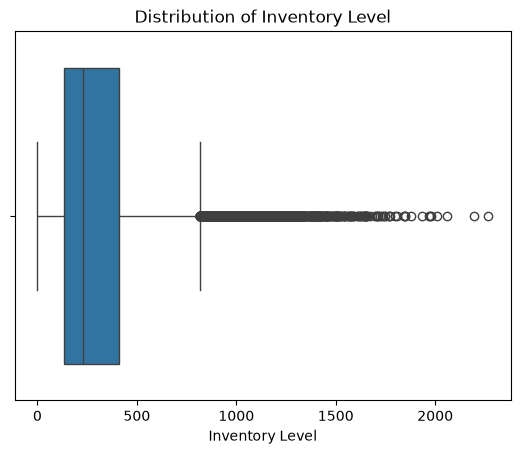

In [54]:
# Creating a visual representation of the Inventory Level distribution
sns.boxplot(data=df, x="Inventory Level")
plt.title("Distribution of Inventory Level")
plt.show()

In [55]:
# Calculating the IQR
Q1_inventory = df["Inventory Level"].quantile(0.25)
Q3_inventory = df["Inventory Level"].quantile(0.75)
IQR_inventory = Q3_inventory-Q1_inventory

In [56]:
# Counting the number of outliers
inventory_outlier = df[((df["Inventory Level"]<Q1_inventory-1.5*IQR_inventory))|(df["Inventory Level"]>(Q3_inventory+1.5*IQR_inventory))]
inventory_outlier_count = inventory_outlier.count()
print(inventory_outlier_count)

Date                  2759
Store ID              2759
Product ID            2759
Category              2759
Region                2759
Inventory Level       2759
Units Sold            2759
Units Ordered         2759
Price                 2759
Discount              2759
Weather Condition     2759
Promotion             2759
Competitor Pricing    2759
Seasonality           2759
Epidemic              2759
Demand                2759
dtype: int64


#### Units Sold

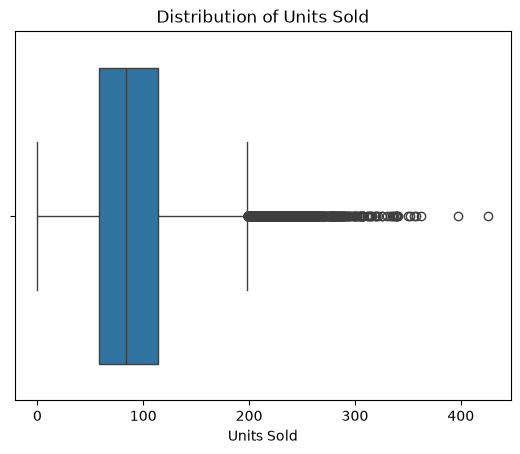

In [57]:
# Creating a visual representation of the Units Sold distribution
sns.boxplot(data=df, x="Units Sold")
plt.title("Distribution of Units Sold")
plt.show()

In [58]:
# Calculating the IQR
Q1_sold = df["Units Sold"].quantile(0.25)
Q3_sold = df["Units Sold"].quantile(0.75)
IQR_sold = Q3_sold-Q1_sold

In [59]:
# Counting the number of outliers
sold_outlier = df[((df["Units Sold"]<Q1_sold-1.5*IQR_sold))|(df["Units Sold"]>(Q3_sold+1.5*IQR_sold))]
sold_outlier_count = sold_outlier.count()
print(sold_outlier_count)

Date                  1411
Store ID              1411
Product ID            1411
Category              1411
Region                1411
Inventory Level       1411
Units Sold            1411
Units Ordered         1411
Price                 1411
Discount              1411
Weather Condition     1411
Promotion             1411
Competitor Pricing    1411
Seasonality           1411
Epidemic              1411
Demand                1411
dtype: int64


#### Units Ordered

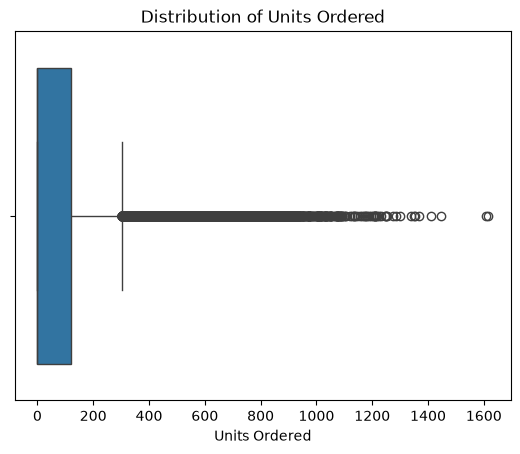

In [60]:
# Creating a visual representation of the Units Ordered distribution
sns.boxplot(data=df, x="Units Ordered")
plt.title("Distribution of Units Ordered")
plt.show()

In [61]:
# Calculating the IQR
Q1_ordered = df["Units Ordered"].quantile(0.25)
Q3_ordered = df["Units Ordered"].quantile(0.75)
IQR_ordered = Q3_ordered-Q1_ordered

In [62]:
# Counting the number of outliers
ordered_outlier = df[((df["Units Ordered"]<Q1_ordered-1.5*IQR_ordered))|(df["Units Ordered"]>(Q3_ordered+1.5*IQR_ordered))]
ordered_outlier_count = ordered_outlier.count()
print(ordered_outlier_count)

Date                  7524
Store ID              7524
Product ID            7524
Category              7524
Region                7524
Inventory Level       7524
Units Sold            7524
Units Ordered         7524
Price                 7524
Discount              7524
Weather Condition     7524
Promotion             7524
Competitor Pricing    7524
Seasonality           7524
Epidemic              7524
Demand                7524
dtype: int64


#### Demand 

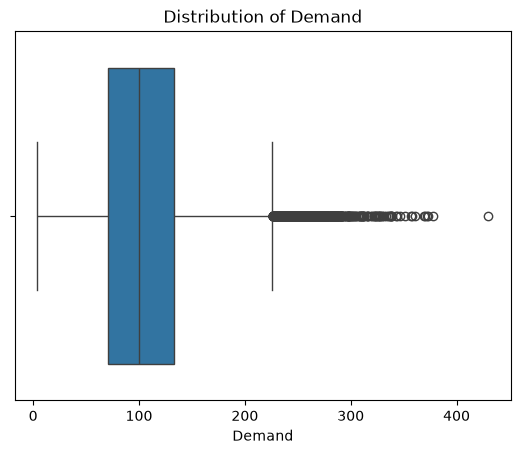

In [63]:
# Creating a visual representation of the Demand distribution
sns.boxplot(data=df, x="Demand")
plt.title("Distribution of Demand")
plt.show()

In [64]:
# Calculating the IQR
Q1_demand = df["Demand"].quantile(0.25)
Q3_demand = df["Demand"].quantile(0.75)
IQR_demand = Q3_demand-Q1_demand

In [65]:
# Counting the number of outliers
demand_outlier = df[((df["Demand"]<Q1_demand-1.5*IQR_demand))|(df["Demand"]>(Q3_demand+1.5*IQR_demand))]
demand_outlier_count = demand_outlier.count()
print(demand_outlier_count)

Date                  986
Store ID              986
Product ID            986
Category              986
Region                986
Inventory Level       986
Units Sold            986
Units Ordered         986
Price                 986
Discount              986
Weather Condition     986
Promotion             986
Competitor Pricing    986
Seasonality           986
Epidemic              986
Demand                986
dtype: int64


#### Outlier Evaluation
The boxplots and IQR calculations reveal a significant number of outliers in this dataset with up to 16% of the data points being outliers. It is important to address these outliers to prevent them from skewing the data and predictions. There are various options, such as directly removing the outliers, capping values to a specific percentile, or substituting the entries with another form of measurement such as mean or median. I do not want to outrightly delete all of the values since 16% is a significant portion of the total data. I will create an upper and lower cap for the outliers. However, it is important to recognize that this risks a loss in data variability and may create a blind spot for the predictive models later on.

### Handling Outliers 

#### Inventory Level

In [66]:
# Setting the lower and upper limit 
lower_inventory = df["Inventory Level"].quantile(0.05)
upper_inventory = df["Inventory Level"].quantile(0.95) 

In [67]:
# Capping Inventory Level within the set range
df["Inventory Level"] = df["Inventory Level"].clip(lower=lower_inventory)
df["Inventory Level"] = df["Inventory Level"].clip(upper=upper_inventory)

#### Units Sold

In [68]:
# Setting the lower and upper limit 
lower_sold = df["Units Sold"].quantile(0.05)
upper_sold = df["Units Sold"].quantile(0.95) 

In [69]:
# Capping Unit Sold within the set range
df["Units Sold"] = df["Units Sold"].clip(lower=lower_sold)
df["Units Sold"] = df["Units Sold"].clip(upper=upper_sold)

#### Units Ordered

In [70]:
# Setting the lower and upper limit 
lower_ordered = df["Units Ordered"].quantile(0.05)
upper_ordered = df["Units Ordered"].quantile(0.95) 

In [71]:
# Capping Unit Ordered within the set range
df["Units Ordered"] = df["Units Ordered"].clip(lower=lower_ordered)
df["Units Ordered"] = df["Units Ordered"].clip(upper=upper_ordered)

#### Demand 

In [72]:
# Setting the lower and upper limit 
lower_demand = df["Demand"].quantile(0.05)
upper_demand = df["Demand"].quantile(0.95) 

In [73]:
# Capping Demand within the set range
df["Demand"] = df["Demand"].clip(lower=lower_demand)
df["Demand"] = df["Demand"].clip(upper=upper_demand)

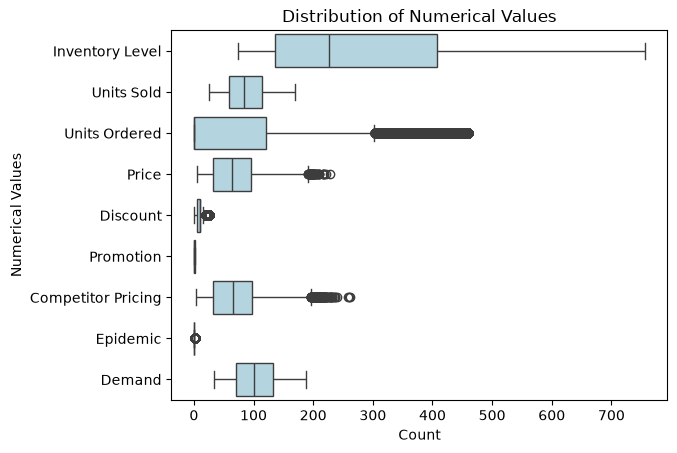

In [74]:
# Checking to see if outliers have been removed 
sns.boxplot(data=df, color="lightblue", orient="h")
plt.title("Distribution of Numerical Values")
plt.xlabel("Count")
plt.ylabel("Numerical Values")
plt.show()

### Justification
To address outliers, each of the variables were capped at the 5th and 95th percentiles. These caps were created because there were a significant amount of outliers in the data, up to 16% of all rows. I did not want to delete that amount of valuable data without knowing if it was done in error or if it were actually extreme values. Additionally, I did not want to substitute each of the outlier variables with central tendency measurements because I still wanted the data points to reflect the significant increase or decrease in the values. These key variables were already skewed and so capping the outliers at the 5th and 95th percentiles were in the best interest for accuracy in visualizations, analysis, and future predictions. 

### Checking for Inconsistencies in Categorical Variables

#### Category

In [75]:
df["Category"].value_counts()

Category
Groceries      30400
Furniture      13680
Clothing       12160
Toys           10640
Electronics     9120
Name: count, dtype: int64

#### Region

In [76]:
df["Region"].value_counts()

Region
North    30400
South    15200
East     15200
West     15200
Name: count, dtype: int64

#### Weather Condition

In [77]:
df["Weather Condition"].value_counts()

Weather Condition
Cloudy    24360
Sunny     22980
Rainy     17500
Snowy     11160
Name: count, dtype: int64

#### Seasonality

In [78]:
df["Seasonality"].value_counts()

Seasonality
Winter    21000
Spring    18400
Summer    18400
Autumn    18200
Name: count, dtype: int64

#### Justification

The lists of unique values under each categorical column shows how there are no inconsistencies in the data. None of the columns show any unknown or inconsistent spelling of the variable options. While these are not part of my key variables, it is still important to have these categorical variables cleaned to avoid running into future issues or a different analysis.  

In [79]:
# Saving the cleaned version of the dataset

df.to_csv("../data/processed/demand_forecasting_cleaned.csv", index=False)

In [80]:
# Verifying that the cleaned dataset was saved 
# Loading the saved cleaned dataset

cleaned_df = pd.read_csv("../data/processed/demand_forecasting_cleaned.csv")
cleaned_df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,188
2,2022-01-01,S001,P0003,Clothing,North,247,114,459,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


In [81]:
cleaned_df.shape

(76000, 16)